# Titanic Survival Prediction — Improved Version

This notebook uses the real Titanic dataset available through Seaborn, proper preprocessing, stratified train/test splitting, and a Random Forest model. The final prediction section uses the exact same preprocessing pipeline as training.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings('ignore')

print('All libraries imported successfully!')

All libraries imported successfully!


## 1. Load the real Titanic dataset

The original notebook created `survived` randomly. That makes the target unrelated to the passenger features. Here we use the actual Titanic passenger data instead.

In [ ]:
df = sns.load_dataset('titanic')

print('Dataset shape:', df.shape)
display(df.head(10))
print('\nMissing values:')
print(df.isnull().sum())

Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False



Missing values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [ ]:
# Select useful Titanic features.
# deck is omitted because it contains many missing values.
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
X = df[features].copy()
y = df['survived'].astype(int)

print('Features:')
print(X.head())
print('\nTarget distribution:')
print(y.value_counts())

Features:
   pclass     sex   age  sibsp  parch     fare embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target distribution:
survived
0    549
1    342
Name: count, dtype: int64


## 2. Preprocessing pipeline

Numeric missing values are filled with the median. The categorical columns are filled with their most frequent value and one-hot encoded. Keeping preprocessing inside a pipeline prevents train/test leakage and ensures new passenger inputs are transformed exactly like the training data.

In [ ]:
numeric_features = ['pclass', 'age', 'sibsp', 'parch', 'fare']
categorical_features = ['sex', 'embarked']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Training data:', X_train.shape)
print('Testing data :', X_test.shape)

Training data: (712, 7)
Testing data : (179, 7)


## 3. Train a Random Forest classifier

In [ ]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=400,
        max_depth=6,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print('=' * 50)
print('       RANDOM FOREST TITANIC RESULTS')
print('=' * 50)
print(f'Training Accuracy : {accuracy_score(y_train, y_train_pred):.4f}')
print(f'Testing Accuracy  : {accuracy_score(y_test, y_test_pred):.4f}')

print('\nClassification Report:')
print(classification_report(
    y_test,
    y_test_pred,
    target_names=['Did not survive', 'Survived']
))

       RANDOM FOREST TITANIC RESULTS
Training Accuracy : 0.8778
Testing Accuracy  : 0.8045

Classification Report:
                 precision    recall  f1-score   support

Did not survive       0.83      0.85      0.84       110
       Survived       0.76      0.72      0.74        69

       accuracy                           0.80       179
      macro avg       0.79      0.79      0.79       179
   weighted avg       0.80      0.80      0.80       179



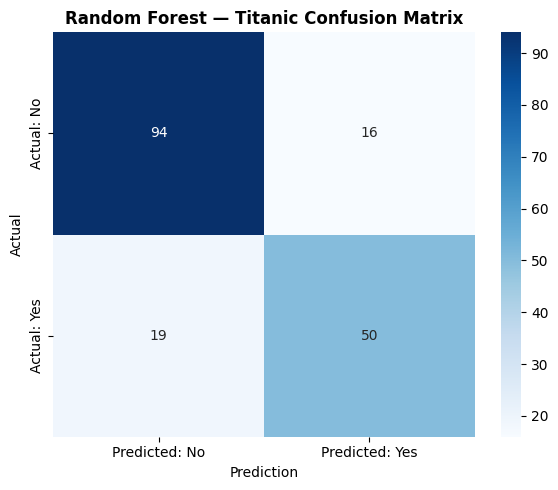

In [ ]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted: No', 'Predicted: Yes'],
    yticklabels=['Actual: No', 'Actual: Yes']
)
plt.title('Random Forest — Titanic Confusion Matrix', fontweight='bold')
plt.xlabel('Prediction')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## 4. Cross-validation

A single train/test split can give a noisy accuracy estimate. Five-fold stratified cross-validation gives a more stable view.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy', n_jobs=-1)

print('Cross-validation scores:', np.round(cv_scores, 4))
print(f'Mean CV accuracy: {cv_scores.mean():.4f}')
print(f'CV standard deviation: {cv_scores.std():.4f}')

Cross-validation scores: [0.8156 0.8258 0.8146 0.8034 0.8483]
Mean CV accuracy: 0.8216
CV standard deviation: 0.0152


## 5. Predict a new passenger

Enter the passenger's information. **Sex:** `male` or `female`. **Embarked:** `S`, `C`, or `Q`.

In [ ]:
print('Enter passenger information:')

pclass = int(input('Pclass (1, 2, or 3): '))
sex = input('Sex (male/female): ').strip().lower()
age = float(input('Age: '))
sibsp = int(input('SibSp (siblings/spouses aboard): '))
parch = int(input('Parch (parents/children aboard): '))
fare = float(input('Fare: '))
embarked = input('Embarked (S/C/Q): ').strip().upper()

if pclass not in [1, 2, 3]:
    raise ValueError('Pclass must be 1, 2, or 3.')
if sex not in ['male', 'female']:
    raise ValueError('Sex must be male or female.')
if embarked not in ['S', 'C', 'Q']:
    raise ValueError('Embarked must be S, C, or Q.')

new_passenger = pd.DataFrame([{
    'pclass': pclass,
    'sex': sex,
    'age': age,
    'sibsp': sibsp,
    'parch': parch,
    'fare': fare,
    'embarked': embarked
}])

prediction = model.predict(new_passenger)[0]
probabilities = model.predict_proba(new_passenger)[0]
prob_no_survive = probabilities[0] * 100
prob_survive = probabilities[1] * 100

print('\n' + '=' * 50)
print('              PREDICTION RESULT')
print('=' * 50)
print(f"Prediction: {'SURVIVED' if prediction == 1 else 'DID NOT SURVIVE'}")
print(f'Probability of not surviving: {prob_no_survive:.2f}%')
print(f'Probability of surviving    : {prob_survive:.2f}%')
print(f'Prediction confidence       : {max(probabilities) * 100:.2f}%')
print('=' * 50)

Enter passenger information:
Pclass (1, 2, or 3): 1
Sex (male/female): female
Age: 2
SibSp (siblings/spouses aboard): 1
Parch (parents/children aboard): 0
Fare: 10
Embarked (S/C/Q): s

              PREDICTION RESULT
Prediction: SURVIVED
Probability of not surviving: 19.00%
Probability of surviving    : 81.00%
Prediction confidence       : 81.00%


### Important note
The probability shown by the model is a statistical estimate, not a guarantee. This model is for learning machine learning with Titanic data.